In [3]:
# ============================================================
# 06C.1 — LOAD VALIDATED PCA REPRESENTATIONS FROM 06B
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 70)
print("06C PCA ANALYSIS — DATA SETUP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Locate project and artifact directory
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().parents[1]

ARTIFACT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "pca_representations"
)

assert ARTIFACT_DIR.exists(), (
    f"06B artifact directory not found:\n{ARTIFACT_DIR}"
)

print("\nArtifact directory:")
print(ARTIFACT_DIR)


# ------------------------------------------------------------
# 2. Load representation metadata
# ------------------------------------------------------------

with open(
    ARTIFACT_DIR / "representation_metadata.json",
    "r",
    encoding="utf-8"
) as f:
    representation_metadata = json.load(f)


with open(
    ARTIFACT_DIR / "recording_ids.json",
    "r",
    encoding="utf-8"
) as f:
    recording_ids = json.load(f)


# ------------------------------------------------------------
# 3. Representation names
# ------------------------------------------------------------

REPRESENTATION_NAMES = [
    "baseline",
    "distribution_aware",
    "yeo_johnson",
    "block_balanced",
    "ndsi_derived_excluded",
    "ndsi_family_excluded",
]


# ------------------------------------------------------------
# 4. Load arrays and feature names
# ------------------------------------------------------------

PCA_INPUTS = {}
PCA_FEATURE_NAMES = {}

for name in REPRESENTATION_NAMES:

    # Numerical representation
    X = np.load(
        ARTIFACT_DIR / f"{name}.npy"
    )

    PCA_INPUTS[name] = X

    # Feature names
    with open(
        ARTIFACT_DIR / f"{name}_features.json",
        "r",
        encoding="utf-8"
    ) as f:
        PCA_FEATURE_NAMES[name] = json.load(f)


# ------------------------------------------------------------
# 5. Validate observation identity
# ------------------------------------------------------------

expected_n = len(recording_ids)

assert expected_n == 275, (
    f"Expected 275 recordings, found {expected_n}"
)


for name in REPRESENTATION_NAMES:

    X = PCA_INPUTS[name]
    features = PCA_FEATURE_NAMES[name]

    assert X.shape[0] == expected_n, (
        f"{name}: incorrect number of recordings"
    )

    assert X.shape[1] == len(features), (
        f"{name}: feature-name count does not match matrix"
    )

    assert np.isfinite(X).all(), (
        f"{name}: non-finite values detected"
    )


# ------------------------------------------------------------
# 6. Validate expected representation dimensions
# ------------------------------------------------------------

expected_dimensions = {
    "baseline": 50,
    "distribution_aware": 50,
    "yeo_johnson": 50,
    "block_balanced": 50,
    "ndsi_derived_excluded": 48,
    "ndsi_family_excluded": 46,
}

for name, expected_features in expected_dimensions.items():

    actual_features = PCA_INPUTS[name].shape[1]

    assert actual_features == expected_features, (
        f"{name}: expected {expected_features} features, "
        f"found {actual_features}"
    )


# ------------------------------------------------------------
# 7. Build handoff summary
# ------------------------------------------------------------

handoff_rows = []

for name in REPRESENTATION_NAMES:

    X = PCA_INPUTS[name]

    handoff_rows.append({
        "representation": name,
        "n_recordings": X.shape[0],
        "n_features": X.shape[1],
        "finite": np.isfinite(X).all(),
        "feature_names_loaded": len(PCA_FEATURE_NAMES[name])
    })

handoff_summary = pd.DataFrame(handoff_rows)


# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("06B → 06C HANDOFF")
print("=" * 70)

display(handoff_summary)


print("\n" + "=" * 70)
print("06C.1 VALIDATION")
print("=" * 70)

print("✓ Six representations loaded")
print("✓ 275 recordings preserved")
print("✓ Feature dimensions verified")
print("✓ Feature names loaded")
print("✓ No non-finite values")
print("✓ 06B → 06C handoff validated")

print("\nReady for parallel PCA.")

06C PCA ANALYSIS — DATA SETUP

Artifact directory:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\pca_representations

06B → 06C HANDOFF


,representation,n_recordings,n_features,finite,feature_names_loaded
0,baseline,275,50,True,50
1,distribution_aware,275,50,True,50
2,yeo_johnson,275,50,True,50
3,block_balanced,275,50,True,50
4,ndsi_derived_excluded,275,48,True,48
5,ndsi_family_excluded,275,46,True,46



06C.1 VALIDATION
✓ Six representations loaded
✓ 275 recordings preserved
✓ Feature dimensions verified
✓ Feature names loaded
✓ No non-finite values
✓ 06B → 06C handoff validated

Ready for parallel PCA.


In [4]:
# ============================================================
# 06C.2 — PARALLEL PCA FITTING
# ============================================================

from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

print("=" * 70)
print("06C.2 — PARALLEL PCA FITTING")
print("=" * 70)


# ------------------------------------------------------------
# 1. Fit PCA separately to each representation
# ------------------------------------------------------------

PCA_RESULTS = {}

for name in REPRESENTATION_NAMES:

    X = PCA_INPUTS[name]

    pca = PCA(
        n_components=min(X.shape[0], X.shape[1]),
        svd_solver="full",
        random_state=42
    )

    scores = pca.fit_transform(X)

    PCA_RESULTS[name] = {
        "model": pca,
        "scores": scores,
        "components": pca.components_,
        "explained_variance": pca.explained_variance_,
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "singular_values": pca.singular_values_,
    }


# ------------------------------------------------------------
# 2. Validate PCA outputs
# ------------------------------------------------------------

for name in REPRESENTATION_NAMES:

    X = PCA_INPUTS[name]
    result = PCA_RESULTS[name]

    pca = result["model"]
    scores = result["scores"]
    evr = result["explained_variance_ratio"]

    # Shape
    assert scores.shape == X.shape, (
        f"{name}: PCA score shape mismatch"
    )

    assert pca.components_.shape == (
        X.shape[1],
        X.shape[1]
    ), (
        f"{name}: PCA component shape mismatch"
    )

    # Numerical validity
    assert np.isfinite(scores).all(), (
        f"{name}: non-finite PCA scores"
    )

    assert np.isfinite(evr).all(), (
        f"{name}: non-finite explained variance"
    )

    # Explained variance ratios sum to 1
    assert np.isclose(
        evr.sum(),
        1.0,
        atol=1e-10
    ), (
        f"{name}: explained variance ratios do not sum to 1"
    )

    # Components are orthonormal
    component_gram = (
        pca.components_
        @ pca.components_.T
    )

    assert np.allclose(
        component_gram,
        np.eye(X.shape[1]),
        atol=1e-8
    ), (
        f"{name}: PCA components are not orthonormal"
    )


# ------------------------------------------------------------
# 3. Create explained-variance summary
# ------------------------------------------------------------

variance_rows = []

for name in REPRESENTATION_NAMES:

    evr = PCA_RESULTS[name]["explained_variance_ratio"]
    cumulative = np.cumsum(evr)

    row = {
        "representation": name,
        "n_features": len(evr),
        "PC1": evr[0],
        "PC2": evr[1],
        "PC3": evr[2],
        "PC4": evr[3],
        "PC5": evr[4],
        "PC10": evr[9] if len(evr) >= 10 else np.nan,
        "cumulative_5": cumulative[4],
        "cumulative_10": (
            cumulative[9] if len(evr) >= 10 else np.nan
        ),
        "cumulative_20": (
            cumulative[19] if len(evr) >= 20 else np.nan
        ),
    }

    for threshold in [0.50, 0.70, 0.80, 0.90, 0.95]:

        n_pc = np.searchsorted(
            cumulative,
            threshold
        ) + 1

        row[f"PCs_to_{int(threshold * 100)}pct"] = n_pc

    variance_rows.append(row)


pca_variance_summary = pd.DataFrame(variance_rows)


# ------------------------------------------------------------
# 4. First 10 PCs in long format
# ------------------------------------------------------------

pc_rows = []

for name in REPRESENTATION_NAMES:

    evr = PCA_RESULTS[name]["explained_variance_ratio"]
    cumulative = np.cumsum(evr)

    for i in range(min(10, len(evr))):

        pc_rows.append({
            "representation": name,
            "PC": i + 1,
            "explained_variance_ratio": evr[i],
            "cumulative_variance": cumulative[i]
        })


pca_first10 = pd.DataFrame(pc_rows)


# ------------------------------------------------------------
# 5. Display
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXPLAINED VARIANCE SUMMARY")
print("=" * 70)

display(
    pca_variance_summary.round(4)
)


print("\n" + "=" * 70)
print("FIRST 10 PRINCIPAL COMPONENTS")
print("=" * 70)

display(
    pca_first10.round(4)
)


# ------------------------------------------------------------
# 6. Final validation
# ------------------------------------------------------------

assert len(PCA_RESULTS) == 6

print("\n" + "=" * 70)
print("06C.2 VALIDATION PASSED")
print("=" * 70)

print("""
✓ PCA fitted independently to all six representations
✓ PCA score matrices have expected dimensions
✓ No non-finite PCA outputs
✓ Explained variance ratios sum to 1
✓ PCA components are orthonormal
✓ Explained-variance summaries generated

Ready for structural comparison.
""")

06C.2 — PARALLEL PCA FITTING

EXPLAINED VARIANCE SUMMARY


,representation,n_features,PC1,PC2,PC3,PC4,PC5,PC10,cumulative_5,cumulative_10,cumulative_20,PCs_to_50pct,PCs_to_70pct,PCs_to_80pct,PCs_to_90pct,PCs_to_95pct
0,baseline,50,0.2095,0.1219,0.0678,0.0604,0.0546,0.0280,0.5143,0.7057,0.8843,5,10,15,22,29
1,distribution_aware,50,0.2167,0.1384,0.0756,0.0638,0.0565,0.0279,0.5511,0.7382,0.9025,5,9,13,20,27
2,yeo_johnson,50,0.2317,0.1441,0.0758,0.0635,0.0569,0.0264,0.5720,0.7564,0.9102,4,9,12,19,26
3,block_balanced,50,0.1720,0.1667,0.0850,0.0753,0.0694,0.0260,0.5685,0.7509,0.9008,5,9,13,20,27
4,ndsi_derived_excluded,48,0.2161,0.1206,0.0703,0.0599,0.0565,0.0283,0.5234,0.7159,0.8938,5,10,14,21,28
5,ndsi_family_excluded,46,0.2232,0.1217,0.0702,0.0617,0.0530,0.0295,0.5298,0.7211,0.9013,5,10,14,20,27



FIRST 10 PRINCIPAL COMPONENTS


,representation,PC,explained_variance_ratio,cumulative_variance
0,baseline,1,0.2095,0.2095
1,baseline,2,0.1219,0.3315
2,baseline,3,0.0678,0.3993
3,baseline,4,0.0604,0.4597
4,baseline,5,0.0546,0.5143
5,baseline,6,0.0486,0.5629
6,baseline,7,0.0426,0.6055
7,baseline,8,0.0383,0.6438
8,baseline,9,0.0339,0.6776
9,baseline,10,0.0280,0.7057



06C.2 VALIDATION PASSED

✓ PCA fitted independently to all six representations
✓ PCA score matrices have expected dimensions
✓ No non-finite PCA outputs
✓ Explained variance ratios sum to 1
✓ PCA components are orthonormal
✓ Explained-variance summaries generated

Ready for structural comparison.



06C.3 — PCA VARIANCE STRUCTURE


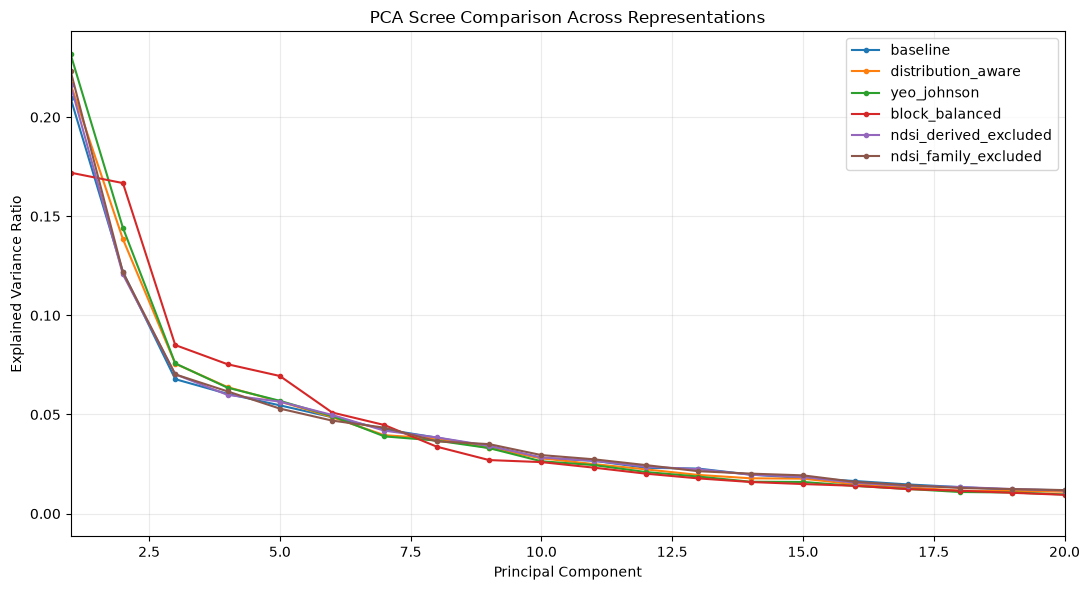

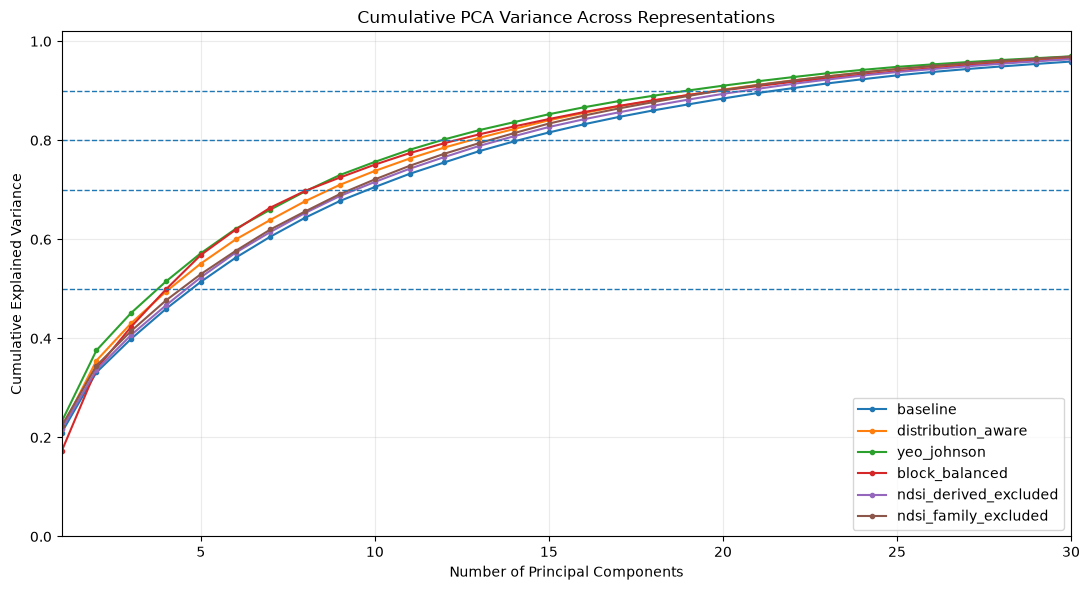


DIMENSIONALITY THRESHOLDS


,representation,PCs_50pct,PCs_70pct,PCs_80pct,PCs_90pct,PCs_95pct
0,baseline,5,10,15,22,29
1,distribution_aware,5,9,13,20,27
2,yeo_johnson,4,9,12,19,26
3,block_balanced,5,9,13,20,27
4,ndsi_derived_excluded,5,10,14,21,28
5,ndsi_family_excluded,5,10,14,20,27



06C.3 COMPLETE


In [5]:
# ============================================================
# 06C.3 — PCA VARIANCE STRUCTURE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=" * 70)
print("06C.3 — PCA VARIANCE STRUCTURE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Prepare plotting data
# ------------------------------------------------------------

plot_rows = []

for name in REPRESENTATION_NAMES:

    evr = PCA_RESULTS[name]["explained_variance_ratio"]
    cumulative = np.cumsum(evr)

    for i in range(len(evr)):

        plot_rows.append({
            "representation": name,
            "PC": i + 1,
            "explained_variance": evr[i],
            "cumulative_variance": cumulative[i]
        })

pca_plot_df = pd.DataFrame(plot_rows)


# ------------------------------------------------------------
# 2. Scree plot
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

for name in REPRESENTATION_NAMES:

    subset = pca_plot_df[
        pca_plot_df["representation"] == name
    ]

    plt.plot(
        subset["PC"],
        subset["explained_variance"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=name
    )

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Comparison Across Representations")
plt.xlim(1, 20)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Cumulative explained variance
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

for name in REPRESENTATION_NAMES:

    subset = pca_plot_df[
        pca_plot_df["representation"] == name
    ]

    plt.plot(
        subset["PC"],
        subset["cumulative_variance"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=name
    )

# Reference thresholds
for threshold in [0.50, 0.70, 0.80, 0.90]:

    plt.axhline(
        threshold,
        linestyle="--",
        linewidth=1
    )

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative PCA Variance Across Representations")
plt.xlim(1, 30)
plt.ylim(0, 1.02)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Compact threshold table
# ------------------------------------------------------------

threshold_rows = []

for name in REPRESENTATION_NAMES:

    evr = PCA_RESULTS[name]["explained_variance_ratio"]
    cumulative = np.cumsum(evr)

    threshold_rows.append({
        "representation": name,
        "PCs_50pct": np.searchsorted(cumulative, 0.50) + 1,
        "PCs_70pct": np.searchsorted(cumulative, 0.70) + 1,
        "PCs_80pct": np.searchsorted(cumulative, 0.80) + 1,
        "PCs_90pct": np.searchsorted(cumulative, 0.90) + 1,
        "PCs_95pct": np.searchsorted(cumulative, 0.95) + 1,
    })

pca_threshold_summary = pd.DataFrame(threshold_rows)

print("\n" + "=" * 70)
print("DIMENSIONALITY THRESHOLDS")
print("=" * 70)

display(pca_threshold_summary)


print("\n" + "=" * 70)
print("06C.3 COMPLETE")
print("=" * 70)

06C.4 — PERMUTATION PARALLEL ANALYSIS

Running: baseline
  Features: 50
  Components above null: 9

Running: distribution_aware
  Features: 50
  Components above null: 9

Running: yeo_johnson
  Features: 50
  Components above null: 9

Running: block_balanced
  Features: 50
  Components above null: 7

Running: ndsi_derived_excluded
  Features: 48
  Components above null: 9

Running: ndsi_family_excluded
  Features: 46
  Components above null: 9

PARALLEL ANALYSIS SUMMARY


,representation,n_features,retained_PCs,first_PC_below_null,PC1_observed,PC1_null_95,PC2_observed,PC2_null_95,PC5_observed,PC5_null_95
0,baseline,50,9,10,10.5151,2.0552,6.1183,1.9250,2.7409,1.7073
1,distribution_aware,50,9,10,10.8754,2.0464,6.9471,1.9199,2.8372,1.7091
2,yeo_johnson,50,9,10,11.6261,2.0474,7.2335,1.9233,2.8550,1.7063
3,block_balanced,50,7,8,1.0356,0.3421,1.0039,0.3120,0.4180,0.2461
4,ndsi_derived_excluded,48,9,10,10.4104,2.0202,5.8109,1.8996,2.7210,1.6834
5,ndsi_family_excluded,46,9,10,10.3062,2.0037,5.6173,1.8800,2.4458,1.6589



PARALLEL ANALYSIS — FIRST 15 COMPONENTS


,representation,PC,observed_eigenvalue,null_mean,null_95pct,retained
0,baseline,1,10.5151,1.9506,2.0552,True
1,baseline,2,6.1183,1.8486,1.9250,True
2,baseline,3,3.4033,1.7738,1.8345,True
3,baseline,4,3.0317,1.7112,1.7672,True
4,baseline,5,2.7409,1.6560,1.7073,True
...,...,...,...,...,...,...
258,ndsi_family_excluded,11,1.2652,1.3449,1.3810,False
259,ndsi_family_excluded,12,1.1294,1.3075,1.3418,False
260,ndsi_family_excluded,13,0.9875,1.2718,1.3050,False
261,ndsi_family_excluded,14,0.9314,1.2371,1.2668,False


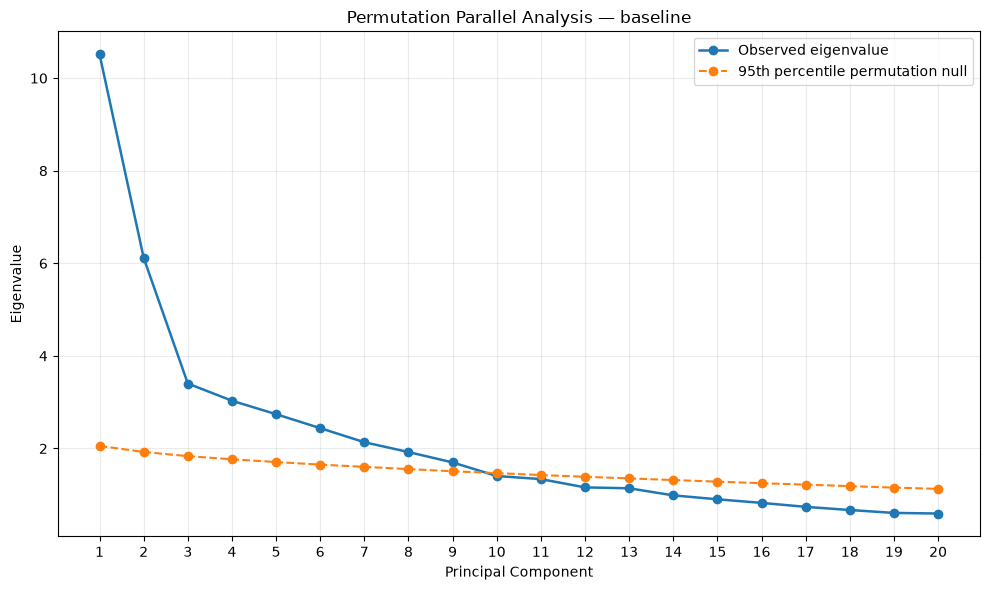

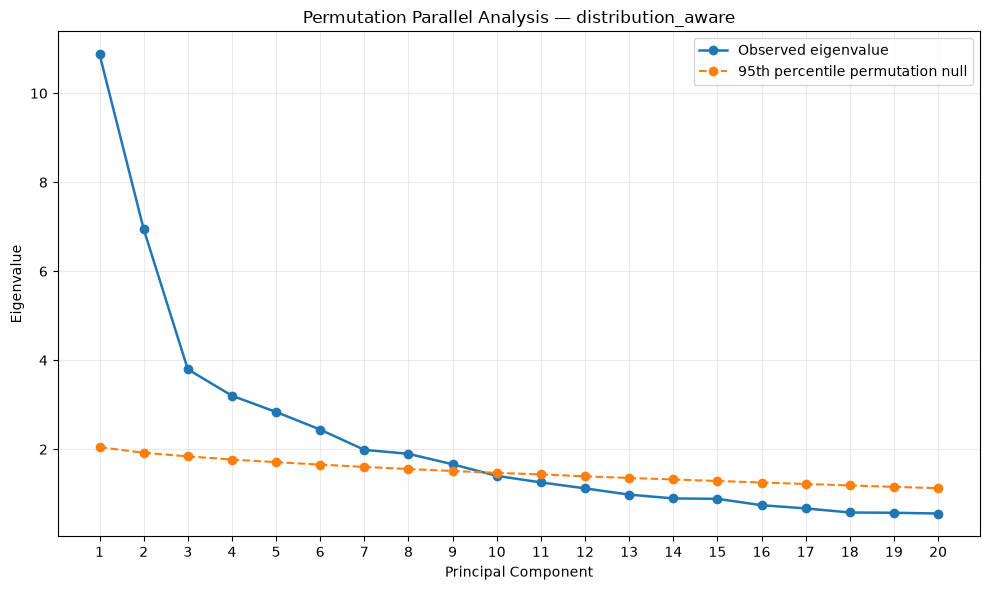

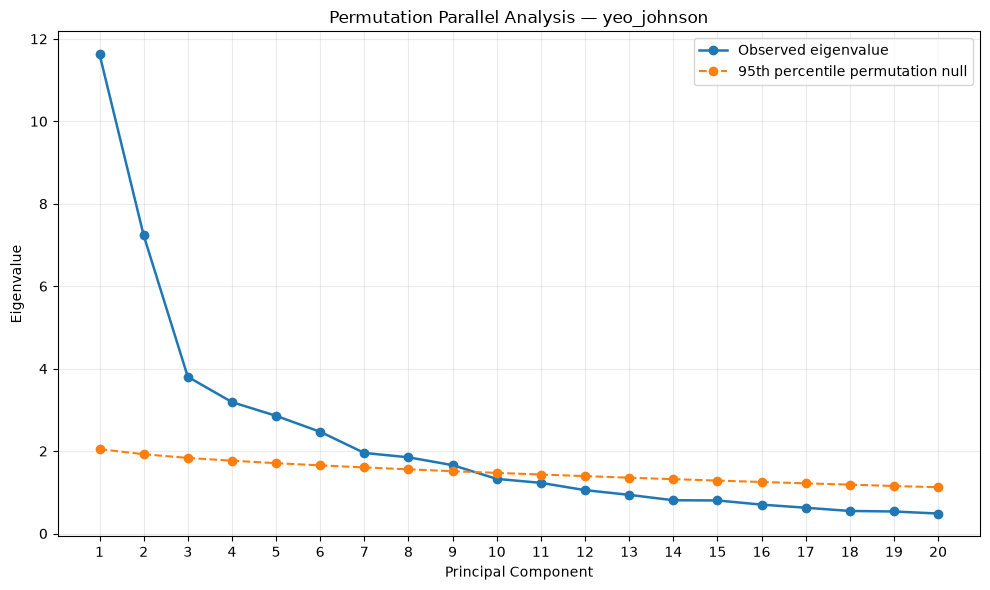

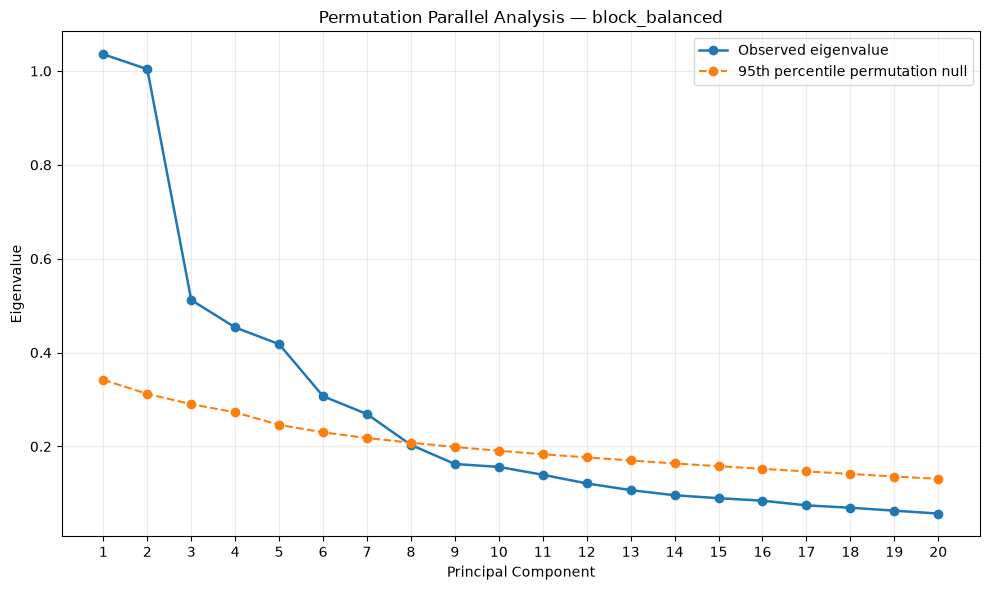

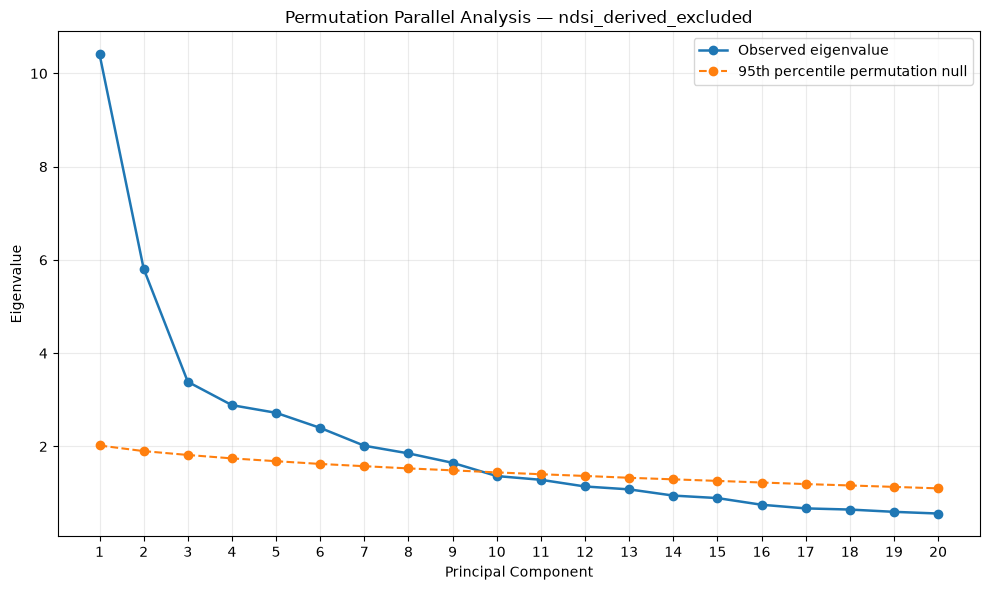

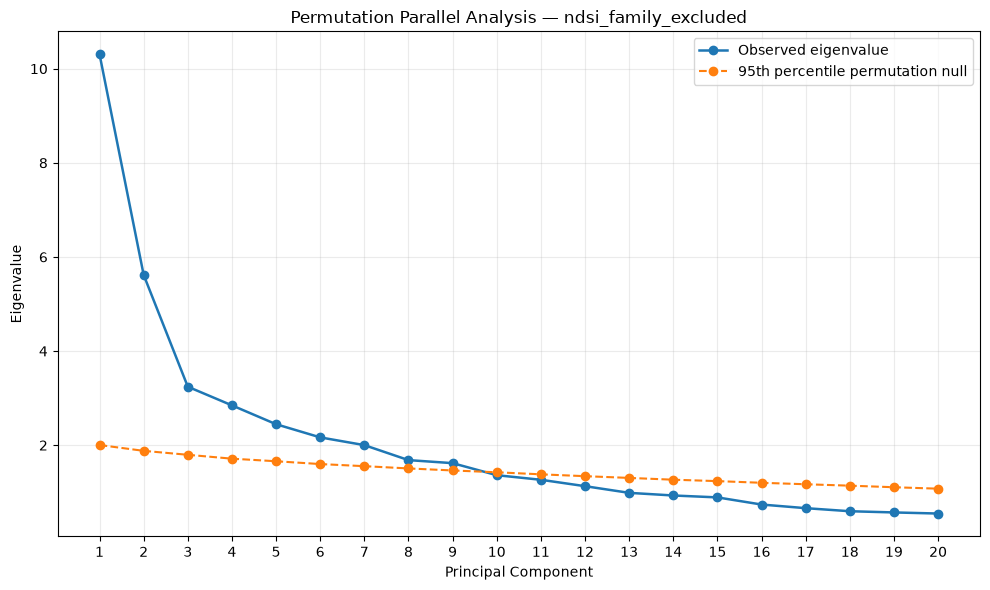


06C.4 VALIDATION PASSED

✓ 1000 permutations per representation
✓ Marginal feature distributions preserved
✓ Cross-feature relationships disrupted
✓ 95th-percentile null threshold calculated
✓ Observed eigenvalues compared against null
✓ Retained-component counts calculated



In [6]:
# ============================================================
# 06C.4 — PERMUTATION PARALLEL ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("06C.4 — PERMUTATION PARALLEL ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

N_PERMUTATIONS = 1000
NULL_PERCENTILE = 95
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)


# ------------------------------------------------------------
# Function: permutation parallel analysis
# ------------------------------------------------------------

def permutation_parallel_analysis(
    X,
    n_permutations=1000,
    percentile=95,
    rng=None
):
    """
    Permutation-based parallel analysis.

    Each feature is independently permuted across observations.
    This preserves each feature's marginal distribution and
    variance while destroying cross-feature relationships.

    Returns:
        observed_eigenvalues
        null_mean
        null_percentile
        retained_components
        null_eigenvalues
    """

    X = np.asarray(X, dtype=float)

    n, p = X.shape

    # Observed covariance eigenvalues
    observed_cov = (
        X.T @ X
    ) / (n - 1)

    observed_eigenvalues = np.linalg.eigvalsh(
        observed_cov
    )[::-1]

    # Null eigenvalues
    null_eigenvalues = np.zeros(
        (n_permutations, p)
    )

    for b in range(n_permutations):

        # Independently permute each feature.
        X_null = np.empty_like(X)

        for j in range(p):
            X_null[:, j] = rng.permutation(X[:, j])

        # Covariance matrix
        cov_null = (
            X_null.T @ X_null
        ) / (n - 1)

        # Eigenvalues
        null_eigenvalues[b, :] = np.linalg.eigvalsh(
            cov_null
        )[::-1]

    # Null summaries
    null_mean = np.mean(
        null_eigenvalues,
        axis=0
    )

    null_percentile_values = np.percentile(
        null_eigenvalues,
        percentile,
        axis=0
    )

    # Retain PCs whose observed eigenvalue exceeds
    # the chosen null percentile.
    retained_components = (
        observed_eigenvalues
        > null_percentile_values
    )

    return {
        "observed_eigenvalues": observed_eigenvalues,
        "null_mean": null_mean,
        "null_percentile": null_percentile_values,
        "retained_components": retained_components,
        "null_eigenvalues": null_eigenvalues,
    }


# ------------------------------------------------------------
# 1. Run parallel analysis for every representation
# ------------------------------------------------------------

PARALLEL_ANALYSIS_RESULTS = {}

for name in REPRESENTATION_NAMES:

    print(f"\nRunning: {name}")

    result = permutation_parallel_analysis(
        PCA_INPUTS[name],
        n_permutations=N_PERMUTATIONS,
        percentile=NULL_PERCENTILE,
        rng=rng
    )

    PARALLEL_ANALYSIS_RESULTS[name] = result

    n_retained = np.sum(
        result["retained_components"]
    )

    print(
        f"  Features: {PCA_INPUTS[name].shape[1]}"
    )

    print(
        f"  Components above null: {n_retained}"
    )


# ------------------------------------------------------------
# 2. Create summary table
# ------------------------------------------------------------

parallel_rows = []

for name in REPRESENTATION_NAMES:

    result = PARALLEL_ANALYSIS_RESULTS[name]

    observed = result["observed_eigenvalues"]
    null_mean = result["null_mean"]
    null_95 = result["null_percentile"]
    retained = result["retained_components"]

    n_retained = int(
        np.sum(retained)
    )

    # First component that fails the criterion
    if n_retained < len(observed):
        first_below_null = n_retained + 1
    else:
        first_below_null = np.nan

    parallel_rows.append({
        "representation": name,
        "n_features": len(observed),
        "retained_PCs": n_retained,
        "first_PC_below_null": first_below_null,
        "PC1_observed": observed[0],
        "PC1_null_95": null_95[0],
        "PC2_observed": observed[1],
        "PC2_null_95": null_95[1],
        "PC5_observed": observed[4],
        "PC5_null_95": null_95[4],
    })

parallel_analysis_summary = pd.DataFrame(
    parallel_rows
)


print("\n" + "=" * 70)
print("PARALLEL ANALYSIS SUMMARY")
print("=" * 70)

display(
    parallel_analysis_summary.round(4)
)


# ------------------------------------------------------------
# 3. Detailed component table
# ------------------------------------------------------------

detail_rows = []

for name in REPRESENTATION_NAMES:

    result = PARALLEL_ANALYSIS_RESULTS[name]

    observed = result["observed_eigenvalues"]
    null_mean = result["null_mean"]
    null_95 = result["null_percentile"]
    retained = result["retained_components"]

    for i in range(len(observed)):

        detail_rows.append({
            "representation": name,
            "PC": i + 1,
            "observed_eigenvalue": observed[i],
            "null_mean": null_mean[i],
            "null_95pct": null_95[i],
            "retained": retained[i]
        })


parallel_analysis_detail = pd.DataFrame(
    detail_rows
)


print("\n" + "=" * 70)
print("PARALLEL ANALYSIS — FIRST 15 COMPONENTS")
print("=" * 70)

display(
    parallel_analysis_detail[
        parallel_analysis_detail["PC"] <= 15
    ].round(4)
)


# ------------------------------------------------------------
# 4. Plot observed vs null threshold
# ------------------------------------------------------------

for name in REPRESENTATION_NAMES:

    result = PARALLEL_ANALYSIS_RESULTS[name]

    observed = result["observed_eigenvalues"]
    null_95 = result["null_percentile"]

    max_pc = min(20, len(observed))

    pcs = np.arange(
        1,
        max_pc + 1
    )

    plt.figure(figsize=(10, 6))

    plt.plot(
        pcs,
        observed[:max_pc],
        marker="o",
        linewidth=1.8,
        label="Observed eigenvalue"
    )

    plt.plot(
        pcs,
        null_95[:max_pc],
        marker="o",
        linestyle="--",
        linewidth=1.5,
        label="95th percentile permutation null"
    )

    plt.xlabel("Principal Component")
    plt.ylabel("Eigenvalue")
    plt.title(
        f"Permutation Parallel Analysis — {name}"
    )

    plt.xticks(pcs)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 5. Validation
# ------------------------------------------------------------

for name in REPRESENTATION_NAMES:

    result = PARALLEL_ANALYSIS_RESULTS[name]

    observed = result["observed_eigenvalues"]
    null_mean = result["null_mean"]
    null_95 = result["null_percentile"]

    assert len(observed) == PCA_INPUTS[name].shape[1]

    assert len(null_mean) == len(observed)

    assert len(null_95) == len(observed)

    assert np.isfinite(observed).all()

    assert np.isfinite(null_mean).all()

    assert np.isfinite(null_95).all()

    # Eigenvalues should be ordered descending.
    assert np.all(
        np.diff(observed) <= 1e-10
    )

    # 95th percentile must be >= null mean.
    assert np.all(
        null_95 >= null_mean - 1e-10
    )


print("\n" + "=" * 70)
print("06C.4 VALIDATION PASSED")
print("=" * 70)

print(f"""
✓ {N_PERMUTATIONS} permutations per representation
✓ Marginal feature distributions preserved
✓ Cross-feature relationships disrupted
✓ 95th-percentile null threshold calculated
✓ Observed eigenvalues compared against null
✓ Retained-component counts calculated
""")

In [7]:
# ============================================================
# 06C.5 — SAVE PCA + PARALLEL ANALYSIS RESULTS
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 70)
print("06C.5 — SAVE PCA ANALYSIS RESULTS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Create artifact directory
# ------------------------------------------------------------

PCA_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "pca_analysis"
)

PCA_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nArtifact directory:")
print(PCA_ARTIFACT_DIR)


# ------------------------------------------------------------
# 2. Save PCA outputs for each representation
# ------------------------------------------------------------

pca_metadata = {}

for name in REPRESENTATION_NAMES:

    result = PCA_RESULTS[name]

    # PCA scores
    np.save(
        PCA_ARTIFACT_DIR / f"{name}_scores.npy",
        result["scores"]
    )

    # PCA loadings/components
    np.save(
        PCA_ARTIFACT_DIR / f"{name}_components.npy",
        result["components"]
    )

    # Explained variance
    np.save(
        PCA_ARTIFACT_DIR / f"{name}_explained_variance.npy",
        result["explained_variance"]
    )

    np.save(
        PCA_ARTIFACT_DIR / f"{name}_explained_variance_ratio.npy",
        result["explained_variance_ratio"]
    )

    # Singular values
    np.save(
        PCA_ARTIFACT_DIR / f"{name}_singular_values.npy",
        result["singular_values"]
    )

    # Feature names
    with open(
        PCA_ARTIFACT_DIR / f"{name}_feature_names.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            PCA_FEATURE_NAMES[name],
            f,
            indent=2
        )

    # Parallel-analysis results
    pa = PARALLEL_ANALYSIS_RESULTS[name]

    np.save(
        PCA_ARTIFACT_DIR / f"{name}_pa_observed_eigenvalues.npy",
        pa["observed_eigenvalues"]
    )

    np.save(
        PCA_ARTIFACT_DIR / f"{name}_pa_null_mean.npy",
        pa["null_mean"]
    )

    np.save(
        PCA_ARTIFACT_DIR / f"{name}_pa_null_95pct.npy",
        pa["null_percentile"]
    )

    np.save(
        PCA_ARTIFACT_DIR / f"{name}_pa_retained.npy",
        pa["retained_components"]
    )

    pca_metadata[name] = {
        "n_recordings": int(
            PCA_INPUTS[name].shape[0]
        ),
        "n_features": int(
            PCA_INPUTS[name].shape[1]
        ),
        "retained_components": int(
            np.sum(pa["retained_components"])
        ),
        "parallel_analysis_permutations": N_PERMUTATIONS,
        "parallel_analysis_percentile": NULL_PERCENTILE
    }


# ------------------------------------------------------------
# 3. Save summary tables
# ------------------------------------------------------------

pca_variance_summary.to_csv(
    PCA_ARTIFACT_DIR / "pca_variance_summary.csv",
    index=False
)

pca_first10.to_csv(
    PCA_ARTIFACT_DIR / "pca_first10.csv",
    index=False
)

parallel_analysis_summary.to_csv(
    PCA_ARTIFACT_DIR / "parallel_analysis_summary.csv",
    index=False
)

parallel_analysis_detail.to_csv(
    PCA_ARTIFACT_DIR / "parallel_analysis_detail.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Save metadata
# ------------------------------------------------------------

with open(
    PCA_ARTIFACT_DIR / "pca_analysis_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        pca_metadata,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 5. Save recording IDs
# ------------------------------------------------------------

with open(
    PCA_ARTIFACT_DIR / "recording_ids.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        recording_ids,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 6. Validate saved artifacts in memory
# ------------------------------------------------------------

for name in REPRESENTATION_NAMES:

    assert (
        PCA_ARTIFACT_DIR
        / f"{name}_scores.npy"
    ).exists()

    assert (
        PCA_ARTIFACT_DIR
        / f"{name}_components.npy"
    ).exists()

    assert (
        PCA_ARTIFACT_DIR
        / f"{name}_pa_observed_eigenvalues.npy"
    ).exists()

    assert (
        PCA_ARTIFACT_DIR
        / f"{name}_pa_null_95pct.npy"
    ).exists()


print("\n" + "=" * 70)
print("06C.5 VALIDATION PASSED")
print("=" * 70)

print("""
✓ PCA scores saved
✓ PCA components saved
✓ Explained variance saved
✓ Feature names saved
✓ Parallel-analysis null results saved
✓ Retained-component decisions saved
✓ Summary tables saved
✓ Recording IDs saved

06C → 06D handoff complete.
""")

06C.5 — SAVE PCA ANALYSIS RESULTS

Artifact directory:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\pca_analysis

06C.5 VALIDATION PASSED

✓ PCA scores saved
✓ PCA components saved
✓ Explained variance saved
✓ Feature names saved
✓ Parallel-analysis null results saved
✓ Retained-component decisions saved
✓ Summary tables saved
✓ Recording IDs saved

06C → 06D handoff complete.

